![logo](https://github.com/HelmholtzAI-Consultants-Munich/XAI-Tutorials/blob/main/docs/source/_figures/Helmholtz-AI.png?raw=true)

In this notebook, you will dive deeper into the attention mechanism and learn how Attention Maps, Attention Rollout, and Attention Flow can help investigate Transformer model predictions.

---

## Getting Started

### Setup Colab environment

If you installed the packages and requirements on your own machine, you can skip this section and start from the import section. Otherwise, you can follow and execute the tutorial on your browser. In order to start working on the notebook, click on the following button, this will open this page in the Colab environment and you will be able to execute the code on your own.

<a href="https://colab.research.google.com/github/HelmholtzAI-Consultants-Munich/XAI-Tutorials/blob/main/xai-for-transformer/2-Tutorial_Attention_Maps_Rollout_Flow.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Now that you opened the notebook in Colab, run the next cell. It fetches the tutorials and installs the requirements.

**Note:** Google Colab may ask you to restart the runtime after installing the required packages. If prompted, restart the runtime before continuing with the notebook.

Running the notebook locally, that cell does nothing: you already have the repository and the requirements.

In [1]:
# On Google Colab: fetch the course and install the requirements.
# Running locally this cell does nothing, because you already have the repository
# and installed the requirements yourself.
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    %cd /content
    !rm -rf XAI-Tutorials
    !git clone --depth 1 --branch main https://github.com/HelmholtzAI-Consultants-Munich/XAI-Tutorials.git
    %cd XAI-Tutorials
    #!pip install -r requirements_xai-for-transformer.txt #TODO: Uncomment when requirements file is ready.
    !pip install -q networkx datasets transformers
    %cd xai-for-transformer

### Imports

In [2]:
%matplotlib inline
import os
import numpy as np
import torch
import networkx as nx
import matplotlib.pyplot as plt

import zipfile
import requests

from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification

# Select the best available device: NVIDIA GPU (CUDA), Apple Silicon GPU (MPS), or CPU
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

# Set seed for reproducibility
torch.manual_seed(0)

print(f"Using device: {device}")


Using device: mps


## Data and Model Loading: The Emotions Dataset

In this notebook, we will work with the **Emotion dataset**, containing English text samples labelled with one of six emotions: **sadness**, **joy**, **love**, **anger**, **fear**, or **surprise**. Each row consists of a short text and its corresponding emotion label. We will use the predefined dataset split, which contains 16,000 training samples, 2,000 validation samples, and 2,000 test samples. Our goal is to **predict the emotion expressed in a text** and use attention-based methods to investigate which words and tokens may contribute to the model's predictions.

<center><img src="https://github.com/HelmholtzAI-Consultants-Munich/XAI-Tutorials/blob/main/docs/source/_figures/dataset_emotions.png?raw=true" width="400" /></center>

In the notebook [*1-Tutorial_Transformer_Model.ipynb*](./1-Tutorial_Transformer_Model.ipynb), we introduced the Transformer architecture and the DistilBERT model used throughout this tutorial.

#### Load the Fine-Tuned Transformer Model

We begin by loading the **fine-tuned DistilBERT model** together with its corresponding tokenizer. The model has been fine-tuned on the Emotion dataset to classify text into one of the six emotion classes.

In [3]:
# Fine-tuned DistilBERT emotion weights, hosted as a GitHub Release asset.
url = "https://github.com/HelmholtzAI-Consultants-Munich/XAI-Tutorials/releases/download/v2.1.0/distilbert_emotion_weights.zip"

data_dir = "../data"
zip_path = f"{data_dir}/distilbert_emotion_weights.zip"
weights_path = f"{data_dir}/distilbert-emotion"

os.makedirs(data_dir, exist_ok=True)

# Download and extract the fine-tuned model weights.
with open(zip_path, "wb") as f:
    f.write(requests.get(url).content)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(data_dir)

os.remove(zip_path)

In [4]:
# Load the fine-tuned DistilBERT model and its matching tokenizer.
# We additionally request the attention weights, which are needed
# for the attention-based methods used in this notebook.

tokenizer = AutoTokenizer.from_pretrained(weights_path)

model = AutoModelForSequenceClassification.from_pretrained(
    weights_path,
    output_attentions=True # Return attention weights for each Transformer layer
).to(device)

model.eval()

print(
    f"Layers: {model.config.num_hidden_layers}, "
    f"heads: {model.config.num_attention_heads}"
)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Layers: 6, heads: 12


**Note**: Before interpreting the model, it is important to verify that it performs reasonably well on the prediction task. As evaluated in the previous tutorial, the fine-tuned DistilBERT model achieves a **balanced accuracy of approximately 0.88 on the test set**. This indicates good overall performance on the Emotion dataset.

## Now, what does my model think is important during the processing of the text?

Now that we have loaded the model and checked its performance, we will explore how attention can help us interpret its predictions.


We will introduce three approaches:
1. Attention Maps
2. Attention Rollout
3. Attention Flow

**Before starting with the practical example, feel free to watch our [video on self attention ](https://xai-tutorials.readthedocs.io/en/latest/_ml_basics/transformer.html#self-attention) to revise the general idea behind the attention mechanism.**

### **1. Attention Maps**

#### **1.1 Intuition: Which tokens attend to which?**

An attention map shows how attention is distributed between token positions within one head of one Transformer layer.

Consider the sentence: *"I feel so anxious and scared about tomorrow"*

For illustration, we use this simplified token sequence: ["I", "feel", "so", "anxious", "and", "scared", "about", "tomorrow"]

When updating the representation at each position, the attention mechanism assigns weights to all token positions, including that position itself. Imagine each token position asking: **“To update my own representation, which token positions should I draw information from, and how strongly?”**

For example, the position “anxious” might assign a high attention weight to “scared.” An attention map lets us inspect these weights for every pair of positions.

#### **1.2 How is an Attention Map Generated?**
For each attention head, each token representation entering the layer is projected into three vectors: a query, a key, and a value. In a matrix form:
$$Q = XW_Q,\qquad K = XW_K,\qquad V = XW_V$$

Here, $X$ contains the token representations entering this layer, and $W_{Q}$, $W_{K}$, and $W_{V}$ are learned projection matrices specific to the head. Each row of $Q$, $K$, and $V$ corresponds to one token position.

Intuitively:

- ***Query***: "What information am I looking for?"
- ***Key***: "How well do I match what you are looking for?"
- ***Value***: "What information do I contribute when attended to?"

Queries and keys determine the attention weights. Those weights are then used to combine the value vectors.

##### **Step 1: Compute Raw Attention Scores**

The model compares every query with every key using a dot product:

$$ QK^T $$

Each entry is a **raw attention score** measuring how strongly each query matches each key.

These scores can be negative or greater than one, and they are not normalized to sum to one.

##### **Step 2: Scale the Scores**

The raw scores are scaled, dividing by the square root of the query/key dimension:

$$ S = \frac{QK^T}{\sqrt{d_k}} $$

where $d_k$ is the dimension of the query and key vectors. Scaling helps prevent the dot-product scores from becoming too large.

##### **Step 3: Apply Softmax**

To convert the scores into attention weights, a softmax is applied across each row:

$$ A_h = \text{softmax(S)} $$

Each row contains the attention weights from one query position to all key positions. These weights are non-negative and sum to one within each row.

The resulting matrix $A_h$ is called an **attention matrix**. Displaying its weights as a heatmap gives an **attention map**.

These weights are used to combine the value vectors:

$$Z_h=A_hV$$

Thus, the map shows the weights used to gather information; the value vectors determine the information being combined.

##### **Step 4: Attention Maps in Multi-Head Attention**

Each attention head produces its own attention matrix and can learn different interaction patterns.

We can inspect individual heads or average their matrices to obtain an overview of attention within a layer:

$$A_{\mathrm{avg}}=\frac{1}{H}\sum_{h=1}^{H}A_h$$

Here, $H$ is the number of heads. Averaging provides a compact summary, but it can hide patterns specific to individual heads.

#### **1.3 Practical example**

#### Extract attention weights and inspect the prediction

To generate the attention scores for a given text, we define a helper function that tokenizes the input, passes it through the model, and returns the **tokens**, the **attention weights from each Transformer layer**, and the **model's prediction logits**.

We will use the same sentence as in the previous example

In [5]:
def get_attentions(text, max_length=24):
    '''Returns tokens, per-layer attentions (tuple of (1, heads, seq, seq)), and logits.'''
    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=max_length
    ).to(device)

    with torch.no_grad():
        outputs = model(**inputs)

    tokens = tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])
    attentions = tuple(a.cpu() for a in outputs.attentions)
    
    return tokens, attentions, outputs.logits.cpu()

In [6]:
text = "i feel so anxious and scared about tomorrow"

tokens, attentions, logits = get_attentions(text)

pred_id = logits.argmax(-1).item()
pred_label = model.config.id2label[pred_id]

print("Tokens:", tokens)
print("Prediction:", pred_label)

Tokens: ['[CLS]', 'i', 'feel', 'so', 'anxious', 'and', 'scared', 'about', 'tomorrow', '[SEP]']
Prediction: fear


We can also display the probability assigned to each emotion.

In [7]:
probs = torch.softmax(logits, dim=-1)[0]
# Display the probability assigned to each emotion class.
for i, prob in enumerate(probs):
    print(f"{model.config.id2label[i]:10s}: {prob.item():.3f}")

sadness   : 0.001
joy       : 0.000
love      : 0.000
anger     : 0.000
fear      : 0.998
surprise  : 0.001


 <font color='green'>

#### 💡 Try it yourself

Replace the example sentence with your own text. Before running the cell, predict which emotion the model will assign to it.

<font color='grey'>

#### Something to consider:

When experimenting with your own sentences, you may encounter predictions that seem unintuitive. This does not necessarily mean that the model performs poorly overall.

The model was fine-tuned on the **Emotion dataset**, which contains only six emotion classes: sadness, joy, love, anger, fear, and surprise. A sentence may express an emotion that is not represented by these classes, may be ambiguous without additional context, or may differ from the types of texts the model encountered during training. In these cases, the model must still assign one of the six available labels.

This highlights an important distinction in XAI: **understanding why a model produced a prediction does not tell us whether that prediction is correct**. Explanation methods help us investigate the model's behaviour, including cases in which that behaviour is unexpected.

In [8]:
# REMOVE FROM STUDENT MATERIAL / Instructor note — optional example illustrating limitations of the label space

# Example of a sentence expressing an emotion that is not represented
# in the model's six-class label space.
new_sentence = "wow that's gross"

new_tokens, new_attentions, new_logits = get_attentions(new_sentence)

# Convert logits to probabilities for all six emotion classes
new_probs = torch.softmax(new_logits, dim=-1)[0]

new_pred_id = new_probs.argmax().item()
new_pred_label = model.config.id2label[new_pred_id]

print(f"Text: {new_sentence}")
print(f"Prediction: {new_pred_label}\n")

# Display the probability assigned to each emotion
for i, prob in enumerate(new_probs):
    print(f"{model.config.id2label[i]:10s}: {prob.item():.3f}")

Text: wow that's gross
Prediction: joy

sadness   : 0.009
joy       : 0.913
love      : 0.001
anger     : 0.041
fear      : 0.008
surprise  : 0.028


#### Visualize attention maps
Now that we have extracted the attention weights, we can visualize how each token position attends to the others and to itself. We define a helper function to display these weights as a heatmap.

We first focus on the first Transformer layer (layer 0) and inspect three heads selected to illustrate different attention patterns for this sentence. You can change which heads are displayed by following the instructions at the end of the code cell.

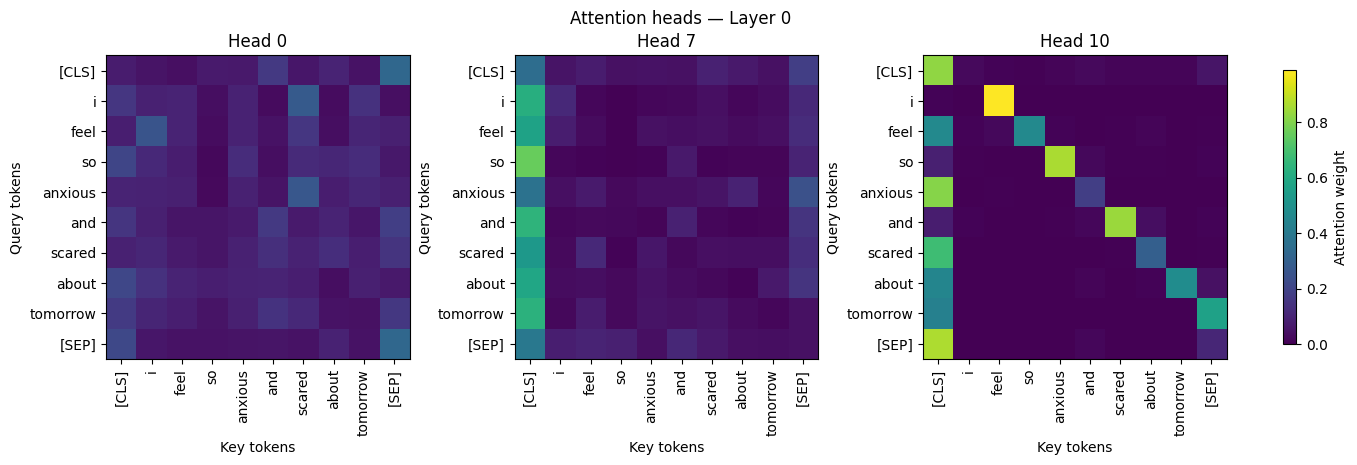

In [9]:
def plot_attention_heads(tokens, attentions, layer=0, heads=(7, 10)):
    # Shape: (num_heads, seq_len, seq_len)
    maps = attentions[layer][0].detach().cpu().numpy()

    ncols = min(3, len(heads))
    nrows = int(np.ceil(len(heads) / ncols))

    fig, axes = plt.subplots(
        nrows, ncols,
        figsize=(4.5 * ncols, 4.5 * nrows),
        squeeze=False,
        constrained_layout=True,
    )

    # Shared color scale across the selected heads.
    vmax = maps[list(heads)].max()

    for ax, head in zip(axes.flat, heads):
        im = ax.imshow(
            maps[head],
            cmap="viridis",
            vmin=0,
            vmax=vmax,
        )
        ax.set_title(f"Head {head}")
        ax.set_xticks(range(len(tokens)))
        ax.set_xticklabels(tokens, rotation=90)
        ax.set_yticks(range(len(tokens)))
        ax.set_yticklabels(tokens)
        ax.set_xlabel("Key tokens")
        ax.set_ylabel("Query tokens")

    # Hide unused panels.
    for ax in axes.flat[len(heads):]:
        ax.axis("off")

    fig.colorbar(
        im,
        ax=list(axes.flat[:len(heads)]),
        label="Attention weight",
        shrink=0.8,
    )
    fig.suptitle(f"Attention heads — Layer {layer}")
    plt.show()


# Change this list to choose which heads to display.
# Head numbers start at 0.
# Examples: [7, 10] for two heads; [0, 7, 10] for three.
# Use list(range(attentions[0].shape[1])) to display every head.
selected_heads = [0, 7, 10]

# Keep all tokens, including [CLS] and [SEP].
plot_attention_heads(tokens, attentions, layer=0, heads=selected_heads)

<font color='green'>

#### Question 1: How do the attention patterns differ across these three heads? Identify one visible pattern in each.

<font color='grey'>

#### Your Answer:

Head 0 distributes attention more broadly across positions. Head 7 shows a prominent vertical band at [CLS], meaning that many query positions attend strongly to it. Head 10 shows a partial diagonal, indicating attention to the query’s own position, alongside attention to [CLS].

These observations describe this sentence and layer; they do not establish fixed roles for these heads.

Individual heads reveal different patterns, but displaying every head for several layers would make comparison difficult. We therefore average the attention matrices across all heads within each layer and display the averages for layers 0, 3, and 5 side by side.

These maps provide a compact overview, although averaging can hide patterns visible in individual heads.

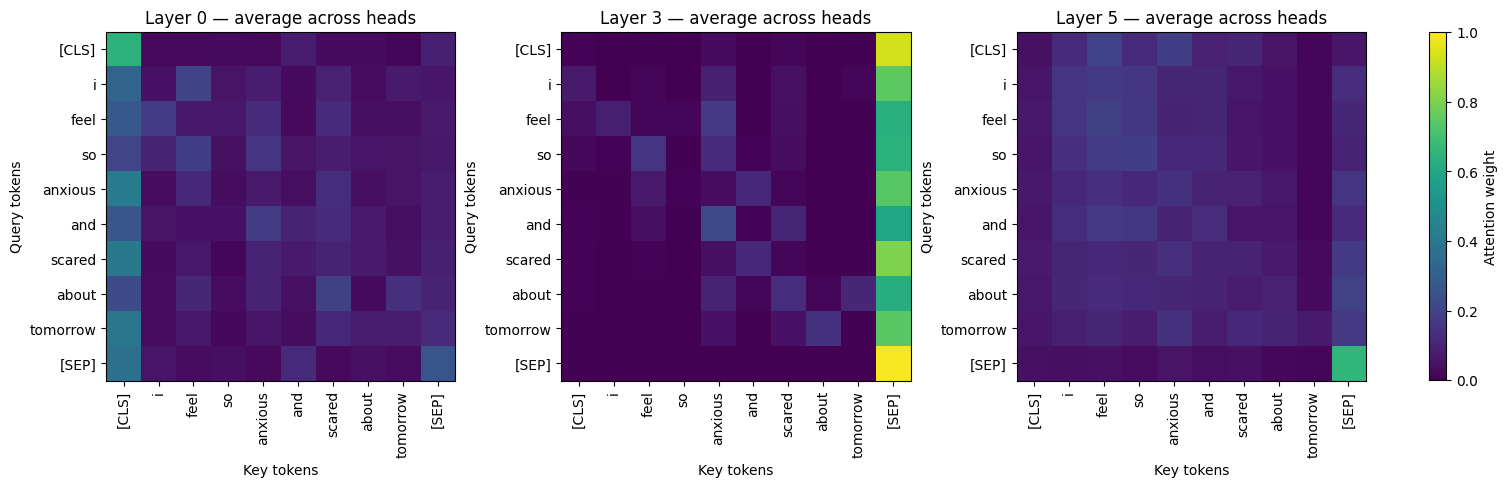

In [10]:
def plot_attention_layers(tokens, attentions, layers=(0, 3, 5)):
    # Use layers=None to display all layers.
    if layers is None:
        layers = range(len(attentions))

    ncols = min(3, len(layers))
    nrows = int(np.ceil(len(layers) / ncols))

    fig, axes = plt.subplots(
        nrows, ncols,
        figsize=(5 * ncols, 5 * nrows),
        squeeze=False,
        constrained_layout=True,
    )

    for ax, layer in zip(axes.flat, layers):
        attn = (
            attentions[layer][0]
            .mean(dim=0)
            .detach()
            .cpu()
            .numpy()
        )

        # Use the same color scale across layers:
        # a weight of 0.2 has the same color in every panel.
        im = ax.imshow(attn, cmap="viridis", vmin=0, vmax=1)

        ax.set_title(f"Layer {layer} — average across heads")
        ax.set_xticks(range(len(tokens)))
        ax.set_xticklabels(tokens, rotation=90)
        ax.set_yticks(range(len(tokens)))
        ax.set_yticklabels(tokens)
        ax.set_xlabel("Key tokens")
        ax.set_ylabel("Query tokens")

    for ax in axes.flat[len(layers):]:
        ax.axis("off")

    fig.colorbar(
        im,
        ax=list(axes.flat[:len(layers)]),
        label="Attention weight",
        shrink=0.8,
    )
    plt.show()


plot_attention_layers(tokens, attentions, layers=(0, 3, 5))

# Optional: show all six layers.
# plot_attention_layers(tokens, attentions, layers=None)

<font color='green'>

#### Question 2: Which token positions receive strong attention from many query positions? Does this change across layers?

<font color='gray'>

#### Your answer:
Describe the visible columns, including [CLS] and [SEP]. A bright special-token column means many query positions assign it a large attention weight.

Because softmax makes each row sum to one, a head must distribute attention even when it has little useful information to gather. Research on BERT suggests that [SEP] can sometimes serve as a default destination when a head’s usual function is not applicable. This is a possible interpretation, not something established by these maps alone.

<font color='green'>

#### Question 3: Inspect the [CLS] row in the final layer. If “anxious” and “scared” do not receive the largest attention weights, can we conclude that the model makes little use of them? Give two reasons.

<font color='gray'>

#### Your answer:

No. First, their information may already have contributed to [CLS] in earlier layers or reached it indirectly through other positions. A single-layer map does not trace these accumulated connections. Rollout and flow approximate connections across layers.

Second, attention weights are only the coefficients used to combine value vectors. A smaller weight can multiply a larger value vector and still produce a substantial contribution to the attention output. Its effect on the final prediction also depends on subsequent computations.

####  1.4 Limitations

Our exploration highlights several limitations of interpreting attention maps:

- **Averaging can hide differences between heads**. A layer’s average map may obscure patterns visible in individual heads.

- **Attention weights are relative**. Softmax makes each row sum to one, so a head must distribute attention even when it has little useful information to gather.

- **Weights alone do not determine the attention output**. The value vectors also determine what information is combined. A small attention weight does not necessarily imply a small contribution: a small weight multiplying a value vector with a large magnitude can still produce a substantial contribution to the attention output.

- **Attention is only part of the computation**. Residual connections, feed-forward networks, and normalization also affect the representations passed through the model.

#### From Attention Maps to Attention Rollout and Attention Flow

Until now, we used Attention Maps to inspect how strongly tokens attend to one another within a particular Transformer layer. These visualizations can provide useful insights into the model's internal information exchange. However, a Transformer consists of multiple stacked layers, and token representations are progressively mixed as information passes through the network. As a result, **attention weights from a single layer do not capture how information from the original input tokens may have propagated through earlier layers**.

To address this limitation, **[Abnar and Zuidema (2020)](https://aclanthology.org/2020.acl-main.385/)** proposed two methods that combine attention information across the Transformer stack: **Attention Rollout** and **Attention Flow**. Both aim to estimate how information from the input tokens reaches representations in deeper layers, using two different strategies:

- **Attention Rollout**: combine attention across layers via matrix multiplication.
- **Attention Flow**: combine attention across layers via a max-flow computation on a graph.

Both methods also incorporate a simplified approximation of residual connections, allowing paths to pass through attention or carry a token’s representation forward directly. However, they still omit value vectors, feed-forward networks, and normalization.

Let's see these different strategies in more detail and compare them on the emotion dataset.

### 2. Attention Rollout

#### 2.1 Definition:

##### **Intuition: From single-layer attention to total influence**

The idea behind Attention Rollout is to capture indirect attention paths across layers. Consider a simple example:

- in layer 1, token **A** attends to token **B**;
- in layer 2, **[CLS]** attends to token **A**.

Even if **[CLS]** never directly attends to **B**, information from **B** can still influence the final **[CLS]** representation because it may have already contributed to **A**'s representation.

Attention Rollout captures these indirect connections by combining attention matrices across layers, providing an estimate of this **accumulated influence**.

#### 2.2 How is an Attention Rollout Map Generated? 

##### **Step 1: Accounting for residual connections**

Because each transformer layer also contains a residual connection, information can flow not only through attention but also directly from one layer to the next.

To account for this, Abnar & Zuidema first add an identity matrix, $I$, to each attention matrix before normalizing it. The identity matrix represents the residual path through which each token carries its own representation forward to the next layer.

$$
\hat{A}^{(l)} = normalize\_rows(A_l + I)
$$


##### **Step 2: Computing the rollout**

The adjusted attention matrices are then multiplied across layers, allowing indirect attention paths to accumulate through the Transformer stack.

$$
R = \hat{A}^{(l)} \times \hat{A}^{(l-1)} \times ... \times \hat{A}^{(1)}
$$

The row corresponding to [CLS] in the final rollout matrix estimates the accumulated attention from the final [CLS] representation to each input token across the Transformer stack.


In [11]:
def compute_rollout(attentions, residual_weight=0.5):
    '''Attention Rollout (Abnar & Zuidema, 2020).
    Returns an (seq, seq) matrix; row i = attribution of every token to token i.
    '''
    seq_len = attentions[0].size(-1)
    result = torch.eye(seq_len)
    for layer_att in attentions:
        A = layer_att[0].mean(dim=0)  # average over heads
        A = (1 - residual_weight) * A + residual_weight * torch.eye(seq_len)
        A = A / A.sum(dim=-1, keepdim=True)
        result = A @ result
    return result


The parameter `residual_weight` controls the balance between attention connections and residual paths. We use `0.5` for both rollout and flow, giving equal weight to the attention matrix and the identity matrix representing residual paths.

In [12]:
rollout = compute_rollout(attentions)
rollout_cls = rollout[0].numpy()  # [CLS] row = attribution for the classification decision

<font color='green'>

#### Question 4: Which tokens would you expect to receive the highest Attention Rollout scores? Would a high Rollout score necessarily mean that a token was important for the model's prediction?

<font color='grey'>

#### Your Answer:

* We might expect emotion-related tokens such as **"anxious"** and **"scared"** to receive high scores, as they are semantically related to the predicted emotion.

* However, a high Attention Rollout score does not necessarily mean that a token was important for the model's prediction. Rollout measures how strongly a token is connected to the final [CLS] representation through accumulated attention paths, rather than directly measuring its effect on the model's output.

We define two helper functions to display one bar per input token, showing its score for connections to the final [CLS] representation. We will use these charts for Attention Rollout, Attention Flow, and the final comparison with last-layer attention. By default, special tokens are excluded and the remaining scores are normalized to sum to one. Set hide_special_tokens=False to include all tokens and display their original scores.

In [13]:
def clean_scores(tokens, scores):
    """Clean a 1D token attribution vector."""
    keep_idx = [
        i for i, t in enumerate(tokens)
        if t not in ("[CLS]", "[SEP]")
    ]

    tokens_clean = [tokens[i] for i in keep_idx]
    scores_clean = np.asarray(scores)[keep_idx]

    if scores_clean.sum() > 0:
        scores_clean /= scores_clean.sum()

    return tokens_clean, scores_clean


def plot_attribution(tokens, scores, color, pred_label, type="Rollout", hide_special_tokens=True):
    if hide_special_tokens:
        tokens_r, scores_r = clean_scores(tokens, scores)
    else:
        tokens_r, scores_r = tokens, np.asarray(scores)

    plt.figure(figsize=(7, 3))
    plt.bar(tokens_r, scores_r, color=color)
    plt.xticks(rotation=45, ha="right")
    plt.ylabel("Normalized score" if hide_special_tokens else "Score")
    plt.title(f"{type} — prediction: {pred_label}")
    plt.tight_layout()
    plt.show()


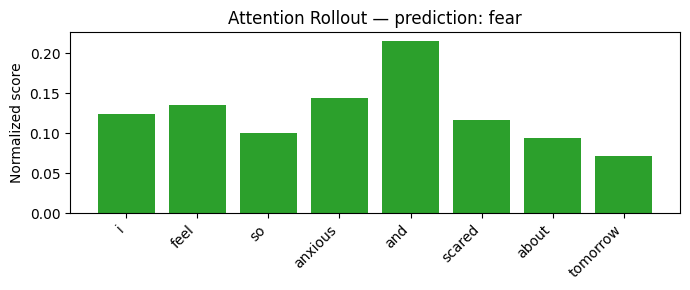

In [14]:
# Visualize the attention rollout attribution for the [CLS] token, which is used for classification.
plot_attribution(tokens, rollout_cls, color="C2", pred_label=pred_label, type="Attention Rollout", hide_special_tokens=True)

<font color='green'>

#### Question 5: Suppose Attention Rollout assigns a higher score to a function word such as "and" than to an emotion-bearing word such as "scared". Does this necessarily mean that "and" was more important for the prediction? What else could explain this result?

<font color='grey'>

#### Your Answer:

* No. A higher Rollout score does not necessarily imply greater importance for the model's prediction.

* Attention Rollout accumulates attention across many paths through the Transformer. A token may therefore receive a high score because it lies on, or is connected through, many attention paths rather than because it carries the main semantic information associated with the prediction.

* This illustrates why Attention Rollout should be interpreted as a view of accumulated attention through the network, rather than as ground truth about which tokens caused the prediction.

### **3. Attention Flow**

#### **3.1 Definition:**

##### **Intuition: From attention paths to constrained flow.**

Like Attention Rollout, Attention Flow considers **how attention propagates across multiple Transformer layers**. However, instead of combining attention matrices through multiplication, it represents the Transformer as a **directed graph**.

<center>
<img src="https://raw.githubusercontent.com/HelmholtzAI-Consultants-Munich/XAI-Tutorials/main/docs/source/_figures/attention-flow-graph.png" width="500" /></center>

In this graph:

- each token representation at each layer is a **node**;
- attention connections between consecutive layers become **edges**;
- attention weights define the **capacity** of each edge.

Unlike Attention Rollout, which accumulates attention across paths, Attention Flow treats each edge as having a limited capacity, determined by its attention weight. You can think of this like water flowing through pipes: each pipe can carry only a certain amount of flow, so a low-capacity edge acts as a bottleneck, limiting how much flow can continue along that path.


#### **3.2 Computing Attention Flow**

For each input token, we compute the **maximum amount of flow** that can reach the final [CLS] representation while respecting the capacity of every edge in the graph. This is known as a **maximum-flow problem**.

More formally, each edge $(l,j) \rightarrow (l+1,i)$ has capacity $\hat{A}^{(l)}_{i,j}$, and the maximum flow is computed from each input token at layer 0 to [CLS] at the final layer.

Because the flow through an edge cannot exceed its capacity, shared paths cannot carry more flow than their bottleneck capacities allow. This provides a different way of aggregating attention across layers than Attention Rollout.

<font color='green'>

#### Question 6: Imagine that several attention paths share the same low-capacity edge. How would you expect Attention Rollout and Attention Flow to treat these paths differently?

<font color='grey'>

#### Your Answer:

* Attention Rollout combines contributions across the different paths, so multiple paths can accumulate attention even when they share the same connection.

* Attention Flow treats the attention weights as capacity constraints. If several paths share a low-capacity edge, the amount of flow that can pass through that connection is limited by its capacity.

* As a result, Attention Flow is less prone to assigning large scores simply because many attention paths pass through the same bottleneck.

**Practical note**. For Attention Flow, we use a smaller residual weight (0.1) than for Attention Rollout (0.5). A larger residual weight gives each token a strong self-connection at every layer, which can make the resulting flow scores less distinguishable across tokens. Using a smaller residual weight reduces this effect and makes differences in the max-flow scores easier to observe.


In [15]:
def compute_attention_flow(attentions, sink_idx=0, residual_weight=0.1):
    '''Attention Flow (Abnar & Zuidema, 2020), simplified: max-flow from each
    input token to `sink_idx` at the final layer.
    '''
    seq_len = attentions[0].size(-1)
    L = len(attentions)
    G = nx.DiGraph()
    for l, layer_att in enumerate(attentions):
        A = layer_att[0].mean(dim=0)
        A = (1 - residual_weight) * A + residual_weight * torch.eye(seq_len)
        A = A / A.sum(dim=-1, keepdim=True)
        A = A.numpy()
        for i in range(seq_len):
            for j in range(seq_len):
                w = float(A[i, j])
                if w > 1e-6:
                    G.add_edge((l, j), (l + 1, i), capacity=w)

    flows = np.zeros(seq_len)
    sink = (L, sink_idx)
    for j in range(seq_len):
        source = (0, j)
        if source == sink:
            flows[j] = 1.0
            continue
        val, _ = nx.maximum_flow(G, source, sink, flow_func=nx.algorithms.flow.edmonds_karp)
        flows[j] = val
    return flows


In [16]:
flow_scores = compute_attention_flow(attentions, sink_idx=0)
tokens_f, scores_f = clean_scores(tokens, flow_scores)

#### Visualizing token attributions

<font color='green'>

#### Question 7: Before visualizing the Attention Flow scores, how do you expect them to differ from the Attention Rollout scores? In particular, what might happen to tokens that received high Rollout scores because they were connected through many attention paths?

<font color='grey'>

#### Your Answer:

* We should not expect the two methods to produce identical attribution patterns because they aggregate attention differently.

* Tokens that receive high Rollout scores because many attention paths contribute to them may receive relatively lower scores with Attention Flow, since shared connections are constrained by their capacities.

* However, we cannot predict the exact ranking of the tokens in advance. The resulting scores depend on the attention structure and capacities throughout the network.

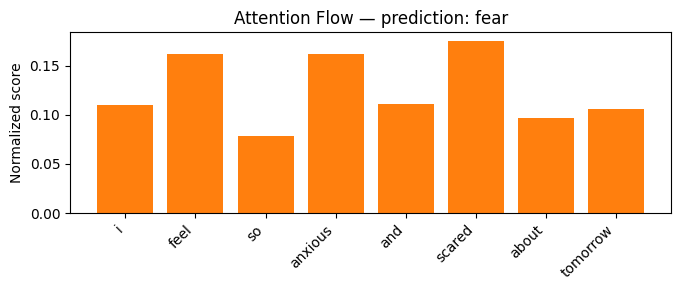

In [17]:
plot_attribution(tokens, flow_scores, color="C1", pred_label=pred_label, type="Attention Flow", hide_special_tokens=True)

## Comparing the three methods 

Let's put **raw last-layer attention**, **Attention rollout**, and **Attention Flow** side by side on the same sentence.

Here, last-layer attention refers to the [CLS] attention weights from the final Transformer layer, averaged across attention heads, without aggregating information across layers.


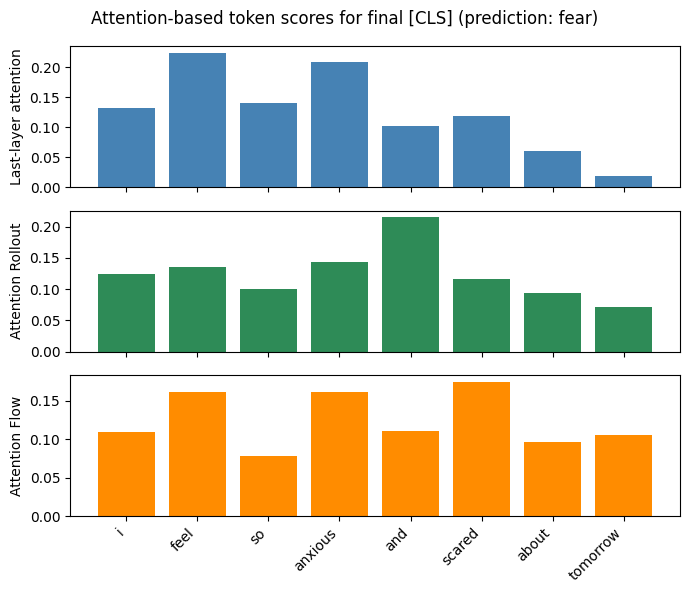

In [18]:
raw_scores = attentions[-1][0].mean(dim=0)[0].numpy()  # last-layer, [CLS] row, head-averaged

tokens_raw, raw_c = clean_scores(tokens, raw_scores)
_, rollout_c = clean_scores(tokens, rollout_cls)
_, flow_c = clean_scores(tokens, flow_scores)

fig, axes = plt.subplots(3, 1, figsize=(7, 6), sharex=True)
for ax, scores, name, color in zip(
    axes,
    [raw_c, rollout_c, flow_c],
    ["Last-layer attention", "Attention Rollout", "Attention Flow"],
    ["steelblue", "seagreen", "darkorange"],
):
    ax.bar(tokens_raw, scores, color=color)
    ax.set_ylabel(name)
plt.xticks(rotation=45, ha="right")
plt.suptitle(f"Attention-based token scores for final [CLS] (prediction: {pred_label})")
plt.tight_layout()
plt.show()


<font color='green'>

#### Question 8: The three methods highlight different tokens. Which conclusions about the model's prediction are supported by these explanations, and which conclusions would be too strong?

<font color='grey'>

#### Your Answer:

* Agreement across multiple methods can provide stronger evidence that a token is involved in the model's internal information flow.

* A token receiving the highest score in one method does not establish that it was the most important token for the prediction.

* Differences between the methods are expected because they aggregate attention according to different assumptions.

* None of these methods provides ground truth about why the model made its prediction.

NOTE FOR THE MENTORS/ TO BE ADDED TO THE SOLUTIONS (more details on the possible answers/plot interpretation)


Each panel is a different, imperfect proxy for "how much did this token matter to the prediction?", they won't fully agree, and that disagreement is itself instructive. A practical way to interpret them together:

1. **Look for convergence across methods.** A token that scores highly across several methods is a useful candidate for further investigation. However, these methods share attention weights and assumptions, so their agreement does not independently establish that the token was important for the prediction.
2. **Treat the single highest bar in any one panel with caution.** Each method has known blind spots, so a token that is top-ranked by rollout alone is less convincing than one that is consistently highlighted across several methods.
3. **Disagreements are teaching moments, not errors.** Different attribution methods make different assumptions, so they may not always highlight the same tokens.
For example, rollout may sometimes assign high attribution to function words such as "and". This happens because rollout aggregates information across many attention paths, which can occasionally overemphasize tokens that connect many paths rather than those carrying the main semantic meaning. Flow is less prone to this because it respects capacity constraints, while last-layer attention only reflects the final layer and may miss information accumulated earlier in the network.
4. **None of the three panels is ground truth.** They're all suggestive signals for generating hypotheses about model behavior — useful for spotting patterns worth investigating further, not for declaring "this is definitely the word that caused the prediction."

### Summary

Things worth remembering:

- **Last-layer attention** shows which positions [CLS] attends to in the final Transformer layer, without tracing connections through earlier layers.

- **Attention Rollout** combines attention across layers by summing products of weights along paths, including approximate residual paths. It is computationally efficient.

- **Attention Flow** combines connections across layers through maximum-flow calculations, treating attention weights as capacities. Shared connections constrain the flow within each calculation, at greater computational cost.

### What do these attention-based methods explain?

Attention Maps, Attention Rollout, and Attention Flow provide different views of the model’s attention connections. Attention maps show attention within individual layers, while rollout and flow approximate connections across layers, including residual paths.

However, none of these methods alone establishes each token’s causal contribution to the model’s prediction:

**Attention weights omit the information being combined**. Value vectors and subsequent transformations also determine what reaches the final representation.

**The methods capture only part of the computation**. Rollout and flow approximate attention and residual paths, but do not account for the full effects of feed-forward networks and normalization.

**The scores are not specific to the predicted class**. Our calculations examine connections to final [CLS]; they do not directly measure a token’s effect on the score for “fear” or another emotion.

**Agreement does not prove correctness**. The methods share attention-based assumptions, so agreement can motivate further investigation without independently validating an explanation.

The paper **“Attention is not Explanation”** from Jain and Wallace (2019) challenges the assumption that high attention automatically identifies the inputs responsible for a prediction. It does not mean that attention visualizations are useless: they can reveal patterns and help formulate hypotheses. Those hypotheses require further evidence.

For a closer discussion, watch our video on Attention is not Explanation (TODO: add link).

---

## Extra: Exploring Attention Rollout on More Examples

So far, we have explored the attention-based methods using a single sentence. As an optional exercise, let's inspect one example from each emotion class and consider how easy (or difficult) it is to interpret the resulting attribution scores.

We focus on **Attention Rollout** here because it is considerably cheaper to compute across multiple examples than Attention Flow. The goal is not to identify the "best" explanation, but to practice critically interpreting attention-based attribution scores.

**Note:** `get_attentions` limits inputs to 24 tokens, including special tokens. Longer examples are truncated, so their predictions and rollout scores refer only to the processed portion, even though the full original text is printed below.

In [19]:
# Load the Emotion dataset for the additional examples
ds = load_dataset("dair-ai/emotion", "split")

In [20]:
def top_k_rollout_tokens(text, k=5):
    """ Returns the predicted label and the top-k tokens with highest rollout attribution scores. """
    toks, atts, logits = get_attentions(text)

    pred_id = logits.argmax(-1).item()
    pred_label = model.config.id2label[pred_id]

    scores = compute_rollout(atts)[0].numpy()
    toks_clean, scores_clean = clean_scores(toks, scores)

    order = np.argsort(-scores_clean)[:k]
    return pred_label, [(toks_clean[i], float(scores_clean[i])) for i in order]

# Inspect the first example of each label in the dataset, and print the top-k tokens with highest rollout attribution scores.
seen = set()

for example in ds["train"]:
    true_label = model.config.id2label[example["label"]]

    if true_label in seen:
        continue

    seen.add(true_label)

    pred_label, top_tokens = top_k_rollout_tokens(example["text"])

    print(f"True: {true_label:8s} | Pred: {pred_label:8s} | Text: {example['text']}")
    print("  Top Rollout tokens:", ", ".join(f"{token} ({score:.2f})" for token, score in top_tokens))
    print()

    if len(seen) == model.config.num_labels:
        break


True: sadness  | Pred: sadness  | Text: i didnt feel humiliated
  Top Rollout tokens: humiliated (0.29), feel (0.20), i (0.19), didn (0.16), ##t (0.16)

True: anger    | Pred: anger    | Text: im grabbing a minute to post i feel greedy wrong
  Top Rollout tokens: greedy (0.13), wrong (0.13), a (0.12), to (0.12), feel (0.11)

True: love     | Pred: love     | Text: i am ever feeling nostalgic about the fireplace i will know that it is still on the property
  Top Rollout tokens: nos (0.09), the (0.07), feeling (0.07), the (0.07), ##tal (0.05)

True: surprise | Pred: fear     | Text: ive been taking or milligrams or times recommended amount and ive fallen asleep a lot faster but i also feel like so funny
  Top Rollout tokens: but (0.09), a (0.08), and (0.08), asleep (0.05), recommended (0.05)

True: fear     | Pred: fear     | Text: i feel as confused about life as a teenager or as jaded as a year old man
  Top Rollout tokens: confused (0.11), feel (0.08), a (0.07), a (0.07), or (0.07)

T

<font color='green'>

#### Question 9

Compare the model predictions with the tokens receiving the highest Attention Rollout scores.

- Do the highest-scoring tokens always have an obvious semantic relationship to the predicted emotion?
- How would you interpret cases where function words such as *"the"*, *"a"*, or *"but"* receive high scores?
- If the model makes an incorrect prediction, can the Rollout scores tell us why it was wrong?


<font color='grey'>

#### Something to consider

The examples illustrate that Attention Rollout does not always provide a simple semantic explanation of a prediction. In some cases, a meaningful content word receives a high score; in others, function words receive substantial attribution even when the model predicts the correct class.

This is not necessarily a contradiction. Rollout measures accumulated attention connectivity across layers, rather than the causal effect of each token on the prediction. A token can therefore receive a high Rollout score because of its position in the attention structure without being the main semantic reason for the predicted emotion.

Similarly, when the model makes an incorrect prediction, unusual Rollout scores may help us identify patterns worth investigating, but they do not establish why the model made the error.

</font>

---


## Reference

Abnar, S., & Zuidema, W. (2020). Quantifying Attention Flow in Transformers. ACL

Jain, S., & Wallace, B. C. (2019). Attention is not Explanation. NAACL-HLT

Wiegreffe, S., & Pinter, Y. (2019). Attention is not not Explanation. EMNLP-IJCNLP

Vig, J. (2019). A Multiscale Visualization of Attention in the Transformer Model. ACL System Demonstrations